In [26]:
!mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.257 seconds
All requested packages already installed.


/tmp/xpython_42/2767750946.py:4: DtypeWarning: Columns (141: ServedActiveDutyInUsArmedForces) have mixed types. Specify dtype option on import or set low_memory=False.
  nhanes = pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")


<Axes: >

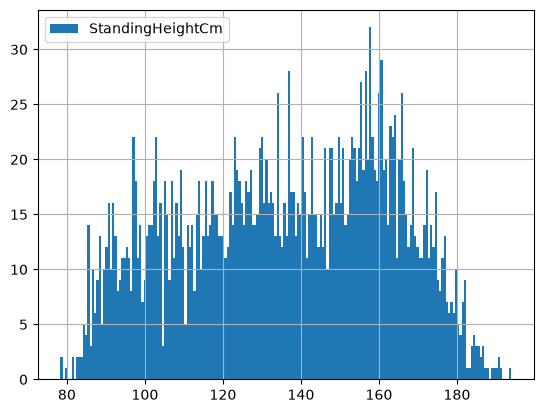

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

nhanes = pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")

children = nhanes[nhanes["AgeInYearsAtScreening"] < 18]

children["StandingHeightCm"].hist(bins=200, legend=True)

<Axes: >

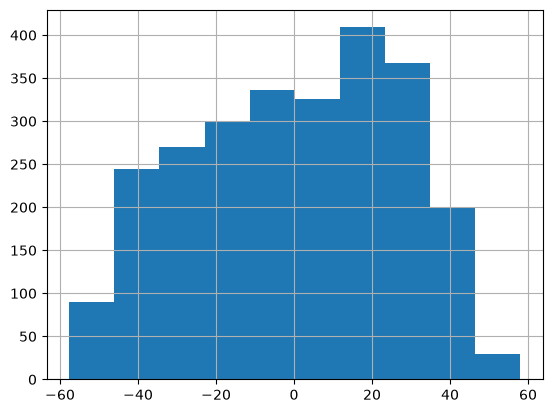

In [5]:
(children["StandingHeightCm"] - children["StandingHeightCm"].mean()).hist()

<Axes: >

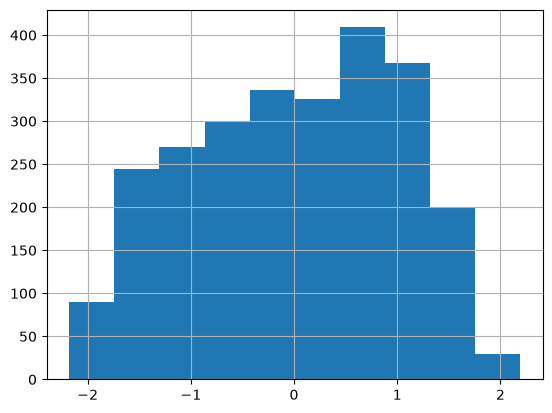

In [6]:
((children["StandingHeightCm"] - children["StandingHeightCm"].mean())/children["StandingHeightCm"].std()).hist()

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

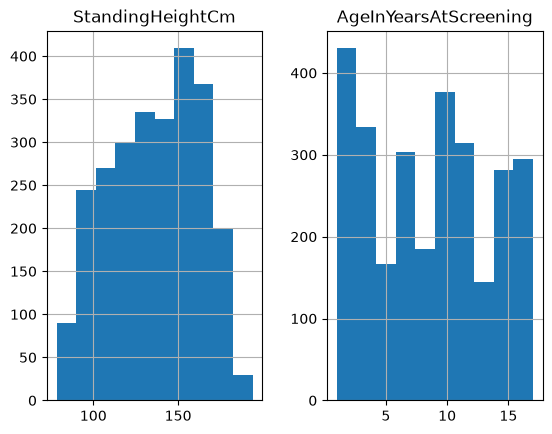

In [7]:
children[["StandingHeightCm","AgeInYearsAtScreening"]].hist()

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

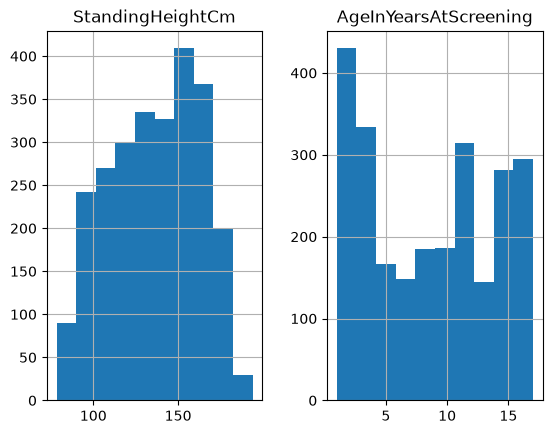

In [8]:
children[["StandingHeightCm","AgeInYearsAtScreening"]].replace([7,9,77,99,777,999,7777,9999], pd.NA).astype("Float64").hist()

In [9]:
children["AgeInYearsAtScreening"].describe()

count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

In [10]:
children["AgeInYearsAtScreening"].dropna().describe()

count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

In [18]:
%pip install seaborn pingouin

mambajs 0.21.4

Process pip requirements ...

Requirement numpy already satisfied.
Requirement pandas already satisfied.
Requirement matplotlib already satisfied.
Requirement packaging already satisfied.
Cannot install 'scikit-learn' from PyPI because it is a binary built package that is not compatible with WASM environments. To resolve this issue, you can: 1) Try to install it from emscripten-forge instead: "!mamba install scikit-learn" 2) If that doesn't work, it's probably that the package was not made WASM-compatible on emscripten-forge. You can either request or contribute a new recipe for that package in https://github.com/emscripten-forge/recipes 
Requirement scipy already satisfied.
Requirement seaborn>=0.13.2 already satisfied.
Cannot install 'statsmodels' from PyPI because it is a binary built package that is not compatible with WASM environments. To resolve this issue, you can: 1) Try to install it from emscripten-forge instead: "!mamba install statsmodels" 2) If that doesn'

<Axes: xlabel='StandingHeightCm', ylabel='BodyMassIndexKgm2'>

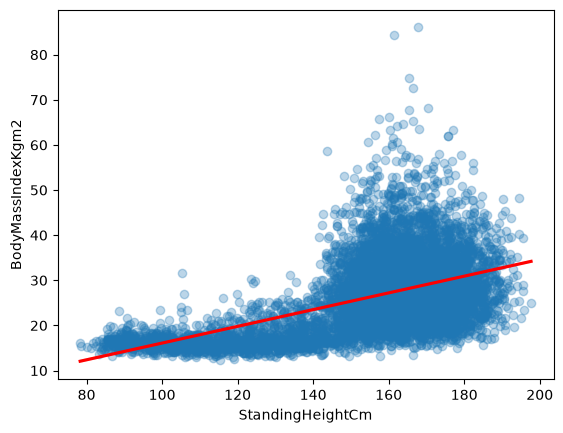

In [25]:
import seaborn as sns
import pingouin as pg
pg.linear_regression(nhanes["StandingHeightCm"], nhanes["BodyMassIndexKgm2"],remove_na=True)
#with vs. without this line:
sns.regplot(data=nhanes,x="StandingHeightCm", y="BodyMassIndexKgm2",scatter_kws={"color": "C0", "alpha": 0.3},line_kws={"color": "red"})

In [52]:
%mamba install scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.448 seconds
All requested packages already installed.


In [55]:
from sklearn.linear_model import LinearRegression

print("scikit-learn is working!")

scikit-learn is working!


In [57]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

children["Gender_code"] = (children["Gender"].astype(str).str.lower().isin(["male", "1"])).astype(int)
children  = children[["StandingHeightCm", "AgeInYearsAtScreening", "Gender_code"]].dropna()

m_age = LinearRegression(fit_intercept=False).fit(children[["AgeInYearsAtScreening"]],children["StandingHeightCm"])
m_age_const = LinearRegression().fit(children[["AgeInYearsAtScreening"]], children["StandingHeightCm"])

m_full = LinearRegression().fit(children[["AgeInYearsAtScreening", "Gender_code"]],children["StandingHeightCm"])
children = children.sort_values("AgeInYearsAtScreening")

children["pred_age"] = m_age.predict(children[["AgeInYearsAtScreening"]])
children["pred_age_const"] = m_age_const.predict(children[["AgeInYearsAtScreening"]])
children["pred_full"] = m_full.predict(children[["AgeInYearsAtScreening", "Gender_code"]])

children["Age_Gender"] = (children["AgeInYearsAtScreening"] * children["Gender_code"])

m_interaction = LinearRegression().fit(children[["AgeInYearsAtScreening","Gender_code","Age_Gender"]],children["StandingHeightCm"])

children["pred_interaction"] = m_interaction.predict(children[["AgeInYearsAtScreening","Gender_code","Age_Gender"]])
fig, ax = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

# A: Original data
ax[0,0].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.2)
ax[0,0].set_title("A. Original data")

# B: Age only
ax[0,1].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.15)
ax[0,1].plot(children["AgeInYearsAtScreening"], children["pred_age"], color="red", lw=3)
ax[0,1].set_title("B. Age")
# C: Age + constant
ax[1,0].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.15)
ax[1,0].plot(children["AgeInYearsAtScreening"], children["pred_age_const"], color="red", lw=3)
ax[1,0].set_title("C. Age + constant")

# D: Age + constant + gender
for g, color, label in [(0, "red", "Female"),(1, "green", "Male")]:
    tmp = children[children["Gender_code"] == g].sort_values("AgeInYearsAtScreening")
    ax[1,1].scatter(tmp["AgeInYearsAtScreening"],tmp["StandingHeightCm"],alpha=.15,color=color)
    ax[1,1].plot(tmp["AgeInYearsAtScreening"],tmp["pred_interaction"],color=color,lw=3,label=label)
ax[1,1].legend()
ax[1,1].set_title("D. Age + constant + gender")

for a in ax.ravel():
    a.set_xlabel("Age (years)")
    a.set_ylabel("Height (cm)")
plt.tight_layout()
plt.show()

<class 'KeyError'>: 'Gender'